<div style='text-align:center;'>
  <img src="single.PNG" width="1200">
</div>

<div style="text-align: center; font-weight: bold; font-size: 22px; color: #1a1a1a;">

  <div style="color: #CC0000; font-size: 30px;">FACILITATOR:</div>
  <div style="color: #000000; font-size: 25px;">VICTOR WANDERA LUMUMBA</div>
  <div style="color: #3D85C6; font-size: 25px;">CDAM, Chuka University, Kenya</div>
  <br>
  <div style="color: #6AA84F; font-size: 20px;">Date:</div>
  <div style="color: #351C75; font-size: 20px;">June 5th, 2026</div>
</div>

#### **Machine Learning Prediction of Customer Churn Status**
Customer churn prediction is a binary classification problem where we estimate the probability that a customer will leave using historical behavioral, transactional, and demographic data.

# Machine Learning Prediction of Customer Churn Status

Customer churn refers to the situation where a customer stops doing business with a company within a given time period. In subscription-based businesses such as telecommunications, banking, insurance, and streaming services, churn directly affects revenue and long-term sustainability. Predicting churn allows organizations to intervene early through retention strategies.

From a machine learning perspective, churn prediction is formulated as a **supervised classification problem**. The target variable is binary:

$$
Y =
\begin{cases}
1 & \text{Customer churned} \
0 & \text{Customer retained}
\end{cases}
$$

Given a feature vector $X = (x_1, x_2, \ldots, x_p)$, the goal is to estimate:

$$
P(Y = 1 \mid X)
$$

A classification threshold $\tau$ (often 0.5) is used to convert probabilities into class labels.

---

## Understanding the Data

The quality of a churn model depends heavily on the available features. Typical churn datasets contain three major categories of variables.

Demographic variables may include age, gender, income level, and location. These variables help segment customers but often have limited predictive power when used alone.

Behavioral variables are usually more informative. These include purchase frequency, average transaction value, number of service interactions, product usage frequency, complaints, and days since last activity. Behavioral features capture engagement patterns and are strong indicators of churn risk.

Contractual or subscription-related variables include tenure (how long the customer has been with the company), contract type, payment method, subscription plan, and renewal history. In many industries, tenure is one of the strongest predictors of churn.

---

## Data Preprocessing

Before model training, the data must be prepared carefully.

Missing values should be handled appropriately. Numerical variables may be imputed using the mean or median, while categorical variables are typically imputed using the mode.

Categorical variables must be encoded into numerical form. Label encoding or one-hot encoding are common approaches. One-hot encoding is generally preferred when categories have no ordinal meaning.

Feature scaling may be necessary for certain algorithms such as Support Vector Machines and Logistic Regression. Standardization transforms features to have mean zero and unit variance.

Churn datasets are often imbalanced, meaning the number of non-churners exceeds churners. In such cases, techniques such as class weighting, oversampling (e.g., SMOTE), or undersampling can be applied to balance the classes.

---

## Model Development

A baseline model such as Logistic Regression is often used first. Logistic Regression models the log-odds of churn as a linear function of predictors:

$$
\log\left(\frac{P(Y=1)}{1 - P(Y=1)}\right) = \beta_0 + \beta_1 x_1 + \cdots + \beta_p x_p
$$

Although simple, it provides interpretability and serves as a benchmark.

Ensemble methods such as Random Forest improve predictive performance by combining multiple decision trees. Random Forest reduces variance through bagging and is robust to noise and non-linear relationships.

Gradient boosting models, particularly XGBoost, often achieve superior performance in churn prediction tasks. Boosting builds trees sequentially, correcting previous errors and minimizing a loss function through gradient descent.

Other algorithms that may be considered include Support Vector Machines and Neural Networks, especially when dealing with high-dimensional or complex data structures.

---

## Model Evaluation

Accuracy alone is not sufficient in churn prediction because of class imbalance. A model predicting all customers as non-churners may still achieve high accuracy.

Key evaluation metrics include precision, recall, F1-score, and ROC-AUC.

Recall (sensitivity) for the churn class is particularly important. It measures the proportion of actual churners correctly identified:

$$
\text{Recall} = \frac{TP}{TP + FN}
$$

Failing to identify a churner represents a lost business opportunity.

The ROC curve plots the True Positive Rate against the False Positive Rate across thresholds. The Area Under the Curve (AUC) provides a threshold-independent performance measure.

---

## Feature Importance and Interpretation

Understanding why a model predicts churn is as important as the prediction itself. Tree-based models provide feature importance measures based on impurity reduction or gain.

More advanced interpretability techniques such as SHAP values allow explanation of individual predictions and quantify each feature’s contribution.

Interpretability is crucial for translating model outputs into actionable business strategies.

---

## Business Application

Once probabilities of churn are estimated, customers can be segmented based on risk levels. High-risk customers may receive targeted retention offers, discounts, or personalized communication. Medium-risk customers may be engaged through loyalty programs, while low-risk customers require minimal intervention.

The classification threshold can be adjusted depending on the business cost of false positives and false negatives. If losing a customer is expensive, a lower threshold may be chosen to capture more potential churners.

---

## Extensions

More advanced approaches include survival analysis for modeling time-to-churn, time-series modeling for behavioral trends, and ensemble stacking for improved predictive performance.

In practice, churn prediction is not only a modeling problem but also a strategic decision-making tool. The ultimate goal is not just high accuracy, but maximizing customer lifetime value and organizational profitability.



##### **Load the Required Libraries**|

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pandas.plotting import scatter_matrix
from mpl_toolkits.mplot3d import Axes3D
import warnings
warnings.filterwarnings('ignore')

#### **Set up the Graphical Display**

In [2]:
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = [10, 6]
plt.rcParams['font.size'] = 10

#### **Read the Imported Data as Data Frame**

In [3]:
df  = pd.read_csv('churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


#### **Check the Data Structure**

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


#### **Change the Total Charges From Object  to Numeric (Or Simply Coerce it to Numeric)**

In [5]:
df['TotalCharges']= pd.to_numeric(df['TotalCharges'], errors = 'coerce')
mean_total_charges = df['TotalCharges'].mean()
df['TotalCharges'].fillna(mean_total_charges, inplace = True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


#### **Convert all Object Variables to Categorical**

In [6]:
for obj in df.columns:
  if df[obj].dtype == 'object':
    df[obj] = df[obj].astype('category')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   customerID        7043 non-null   category
 1   gender            7043 non-null   category
 2   SeniorCitizen     7043 non-null   int64   
 3   Partner           7043 non-null   category
 4   Dependents        7043 non-null   category
 5   tenure            7043 non-null   int64   
 6   PhoneService      7043 non-null   category
 7   MultipleLines     7043 non-null   category
 8   InternetService   7043 non-null   category
 9   OnlineSecurity    7043 non-null   category
 10  OnlineBackup      7043 non-null   category
 11  DeviceProtection  7043 non-null   category
 12  TechSupport       7043 non-null   category
 13  StreamingTV       7043 non-null   category
 14  StreamingMovies   7043 non-null   category
 15  Contract          7043 non-null   category
 16  PaperlessBilling  7043 n

#### **Visualization of the Target Variable**

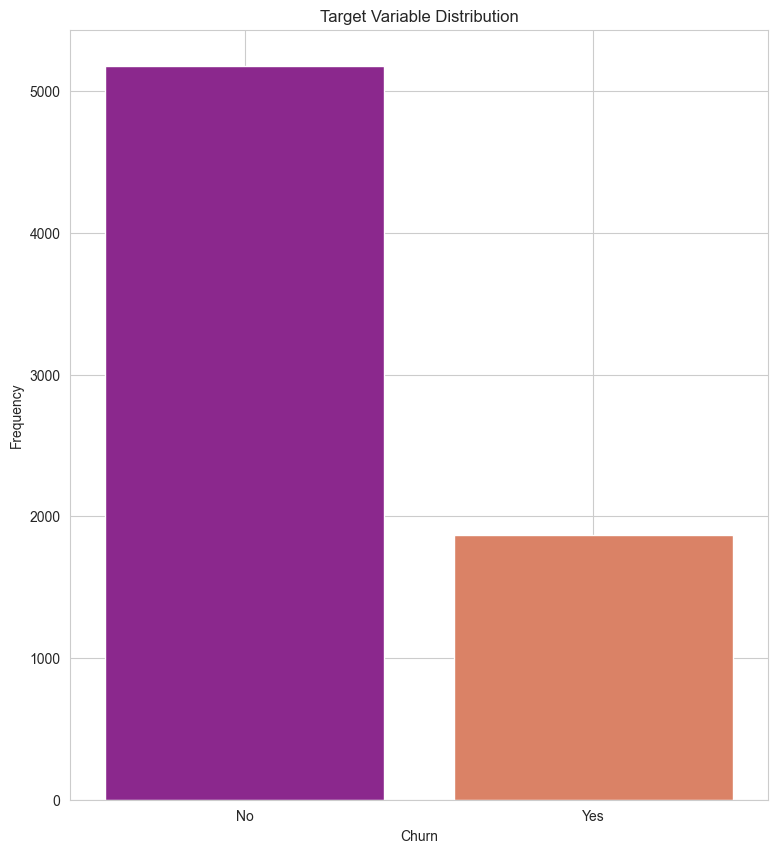

In [8]:
plt.figure(figsize=(9,10))
ax = sns.countplot(x='Churn', data = df, palette = 'plasma')
plt.title('Target Variable Distribution')
plt.xlabel('Churn')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

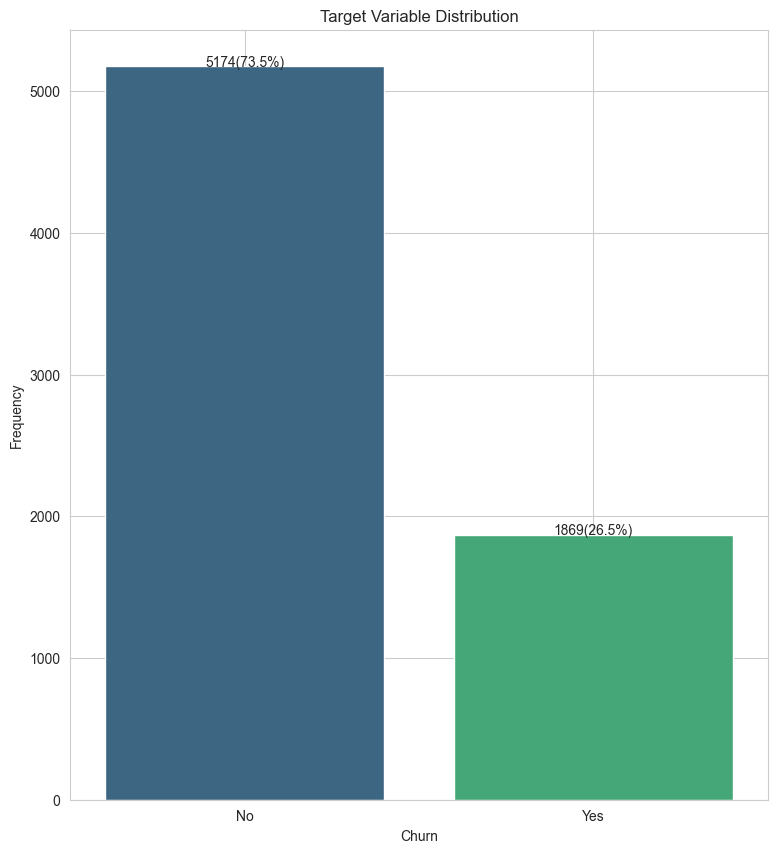

In [9]:
plt.figure(figsize=(9,10))
ax = sns.countplot(x='Churn', data = df, palette = 'viridis')
plt.title('Target Variable Distribution')
plt.xlabel('Churn')
plt.ylabel('Frequency')

total = len(df['Churn'])
for p in ax.patches:
  height = p.get_height()
  ax.text(p.get_x()+p.get_width()/2.,
          height +3,
          f'{int(height)}({(height/total)*100:.1f}%)',
          ha='center')

plt.grid(True)
plt.show()

### **Check for the Missing Values**

In [10]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

### **Create the Target Variable and the Preddictor Matrix**

In [11]:
X = df.drop(['Churn','customerID'], axis =1)
y = df['Churn']

#### **View the X-Matrix and the Target Variable**

In [12]:
X.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


In [13]:
y.head()

0     No
1     No
2    Yes
3     No
4    Yes
Name: Churn, dtype: category
Categories (2, object): ['No', 'Yes']

#### **Create Dummies Variables**

In [14]:
X['MultipleLines'].value_counts()

MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

In [15]:
X['InternetService'].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

In [16]:
X['Contract'].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [17]:
X['PaymentMethod'].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [18]:
X = pd.get_dummies(X, drop_first = True)
X.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,True,False,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,False,False,False,True,False,False,...,False,False,False,False,False,False,True,False,True,False


##### **Convert the One-Hot Encoding to 1 and 0**

In [19]:
X = X.astype(int)
X.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29,29,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56,1889,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53,108,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42,1840,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70,151,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0


In [20]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 30 columns):
 #   Column                                 Non-Null Count  Dtype
---  ------                                 --------------  -----
 0   SeniorCitizen                          7043 non-null   int64
 1   tenure                                 7043 non-null   int64
 2   MonthlyCharges                         7043 non-null   int64
 3   TotalCharges                           7043 non-null   int64
 4   gender_Male                            7043 non-null   int64
 5   Partner_Yes                            7043 non-null   int64
 6   Dependents_Yes                         7043 non-null   int64
 7   PhoneService_Yes                       7043 non-null   int64
 8   MultipleLines_No phone service         7043 non-null   int64
 9   MultipleLines_Yes                      7043 non-null   int64
 10  InternetService_Fiber optic            7043 non-null   int64
 11  InternetService_No            

## **Split the Data into Training and Testing**

In [21]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, 
                                                    test_size = 0.3,  ### Test size = 30%
                                                    random_state = 42) ### For Reproducible

In [22]:
X_train.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
1695,0,54,70,3770,1,1,1,1,0,1,...,0,1,0,0,1,0,1,0,1,0
1095,0,1,80,80,1,0,0,1,0,0,...,0,1,0,0,0,0,1,0,1,0
3889,0,13,19,259,1,0,0,1,0,0,...,1,0,1,0,1,0,0,1,0,0
3667,1,24,96,2263,0,1,1,1,0,0,...,0,1,0,1,0,1,1,0,1,0
2902,1,6,74,450,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0


In [23]:
X_test.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
185,0,1,24,24,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
2715,0,41,25,996,1,0,0,1,0,1,...,1,0,1,0,0,0,1,0,0,0
3825,0,52,19,1031,0,1,1,1,0,0,...,1,0,1,0,0,1,0,0,0,1
1807,0,1,76,76,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,1,0
132,0,67,50,3260,1,0,0,1,0,0,...,0,0,0,0,0,1,0,0,0,0


In [24]:
y_train.head()

1695    No
1095    No
3889    No
3667    No
2902    No
Name: Churn, dtype: category
Categories (2, object): ['No', 'Yes']

### **Develop the KNN Model**

In [25]:
y_test.head()

185     Yes
2715     No
3825     No
1807    Yes
132      No
Name: Churn, dtype: category
Categories (2, object): ['No', 'Yes']

### **Train the KNN-Model**

In [26]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

#### **Initialize the Model Training with Automatic selection of k-value**

In [27]:
knn_model = KNeighborsClassifier(n_neighbors = 10)
##knn_model = KNeighborsClassifier()

#### **Train the K-Neighbors Model**

In [28]:
knn_model = knn_model.fit(X_train, y_train)
knn_model

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",10
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


#### **Check the Number of Neighbors**

In [29]:
knn_model.n_neighbors

10

#### **Prediction**

#### **Evaluate the Model Using Training Set**

In [30]:
knn_pred_train = knn_model.predict(X_train)
knn_pred_train[:10]

array(['No', 'Yes', 'No', 'Yes', 'Yes', 'No', 'No', 'No', 'Yes', 'No'],
      dtype=object)

In [31]:
y_train.head(10)

1695     No
1095     No
3889     No
3667     No
2902     No
1630     No
4294     No
1881     No
4710     No
1612    Yes
Name: Churn, dtype: category
Categories (2, object): ['No', 'Yes']

In [32]:
class_report_train = classification_report(y_train, knn_pred_train)
print(class_report_train)

              precision    recall  f1-score   support

          No       0.82      0.95      0.88      3635
         Yes       0.73      0.40      0.52      1295

    accuracy                           0.80      4930
   macro avg       0.78      0.68      0.70      4930
weighted avg       0.80      0.80      0.78      4930



#### **Evaluate the Model Using the Testing Set**

In [33]:
knn_pred = knn_model.predict(X_test)
knn_pred[:10]

array(['Yes', 'No', 'No', 'Yes', 'No', 'No', 'No', 'No', 'No', 'No'],
      dtype=object)

In [34]:
y_test.head(10)

185     Yes
2715     No
3825     No
1807    Yes
132      No
1263    Yes
3732     No
1672     No
811     Yes
2526    Yes
Name: Churn, dtype: category
Categories (2, object): ['No', 'Yes']

#### **Check the Model's Performance**

In [35]:
accuracy = accuracy_score(y_test, knn_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.7880


In [36]:
conf_matrix = confusion_matrix(y_test, knn_pred)
print("Confusion Matrix:")
print(conf_matrix)

Confusion Matrix:
[[1445   94]
 [ 354  220]]


In [85]:
class_report = classification_report(y_test, knn_pred)
print("Classification Report:")
print(class_report)

Classification Report:
              precision    recall  f1-score   support

          No       0.79      0.93      0.86      1531
         Yes       0.66      0.35      0.46       582

    accuracy                           0.77      2113
   macro avg       0.73      0.64      0.66      2113
weighted avg       0.76      0.77      0.75      2113



In evaluating a classification model, several performance metrics are used to assess how well the model distinguishes between classes. In this case, the target variable is customer churn status (“No” = not churned, “Yes” = churned).

**Precision** measures the proportion of predicted positive cases that are actually positive. It answers the question: *Of all customers predicted to churn, how many truly churned?* High precision indicates a low false-positive rate.

**Recall** (also called sensitivity or true positive rate) measures the proportion of actual positive cases that were correctly identified. It answers: *Of all customers who truly churned, how many did the model correctly detect?* High recall means few false negatives.

**F1-score** is the harmonic mean of precision and recall. It balances both metrics and is especially useful when dealing with imbalanced classes. A higher F1-score indicates a better trade-off between precision and recall.

**Support** refers to the number of actual observations in each class within the test dataset.

**Accuracy** measures the overall proportion of correctly classified instances out of all observations. However, it can be misleading in imbalanced datasets.

**Macro average** computes the unweighted mean of precision, recall, and F1-score across classes, treating each class equally.

**Weighted average** computes the mean of these metrics weighted by the number of instances in each class, thus accounting for class imbalance.

### Report of Results

The model achieved an overall **accuracy of 77%**, correctly classifying 1,409 customers. However, the dataset is imbalanced, with 1,036 non-churners (“No”) and 373 churners (“Yes”).

For the **“No” class**, the model performed strongly, with a **precision of 0.83**, meaning 83% of customers predicted as non-churners were correctly identified. The **recall of 0.89** indicates that 89% of actual non-churners were correctly classified. The corresponding **F1-score of 0.86** reflects robust and consistent performance for this majority class.

For the **“Yes” class**, performance was weaker. The **precision of 0.61** indicates that 61% of predicted churners were truly churners. The **recall of 0.48** shows that the model identified only 48% of actual churners, missing more than half of them. The **F1-score of 0.54** reflects this imbalance between precision and recall.

The **macro-average F1-score of 0.70** suggests moderate overall balance across classes, while the **weighted F1-score of 0.77** is higher due to stronger performance on the majority class. Overall, the model performs well for non-churn prediction but requires improvement in detecting churners.


#### **Plot the Confusion Plot**

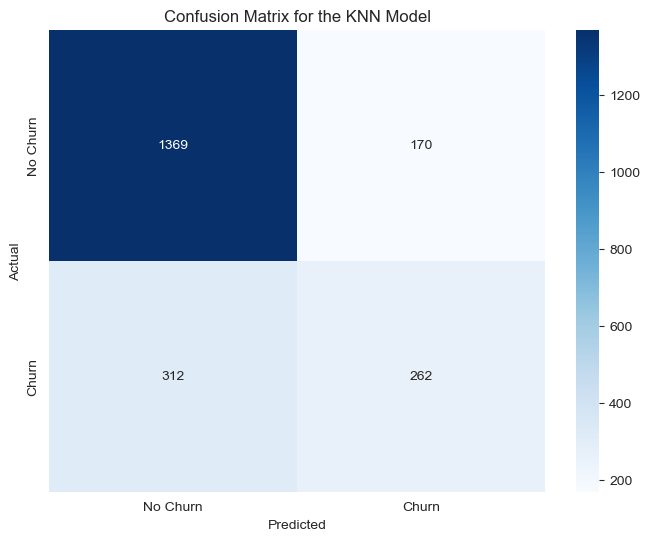

In [111]:
#### plot
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.title('Confusion Matrix for the KNN Model')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [37]:
### Sensitivity 
sens = (262/(262+312))*100
sens

45.64459930313589

In [38]:
### Specificity
spec = (1369 / (1369+170))*100
spec

88.9538661468486

### **ROC and AUC Value**

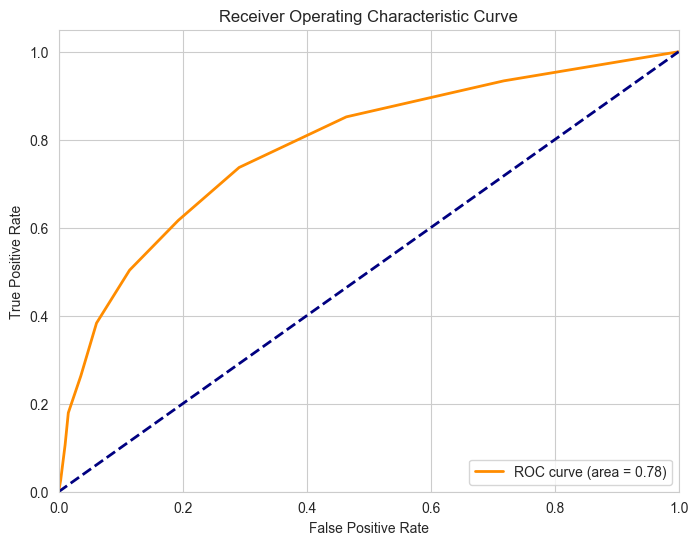

In [39]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

### Calculate ROC
y_test_numeric = y_test.map({'Yes': 1, 'No': 0})
y_pred_prob = knn_model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test_numeric, y_pred_prob)
roc_auc = auc(fpr, tpr)

### Plot
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic Curve')
plt.legend(loc = 'lower right')
plt.grid(True)
plt.show()

### **Featuree Importance Plot**

In [33]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    knn_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42
)
importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': result.importances_mean
})
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)
importance_df

,Feature,Importance
3,TotalCharges,0.115827
2,MonthlyCharges,0.095671
1,tenure,0.008801
0,SeniorCitizen,0.001632
10,InternetService_Fiber optic,0.000852
23,StreamingMovies_Yes,0.000710
13,OnlineSecurity_Yes,0.000497
17,DeviceProtection_Yes,0.000284
9,MultipleLines_Yes,0.000213
24,Contract_One year,0.000071


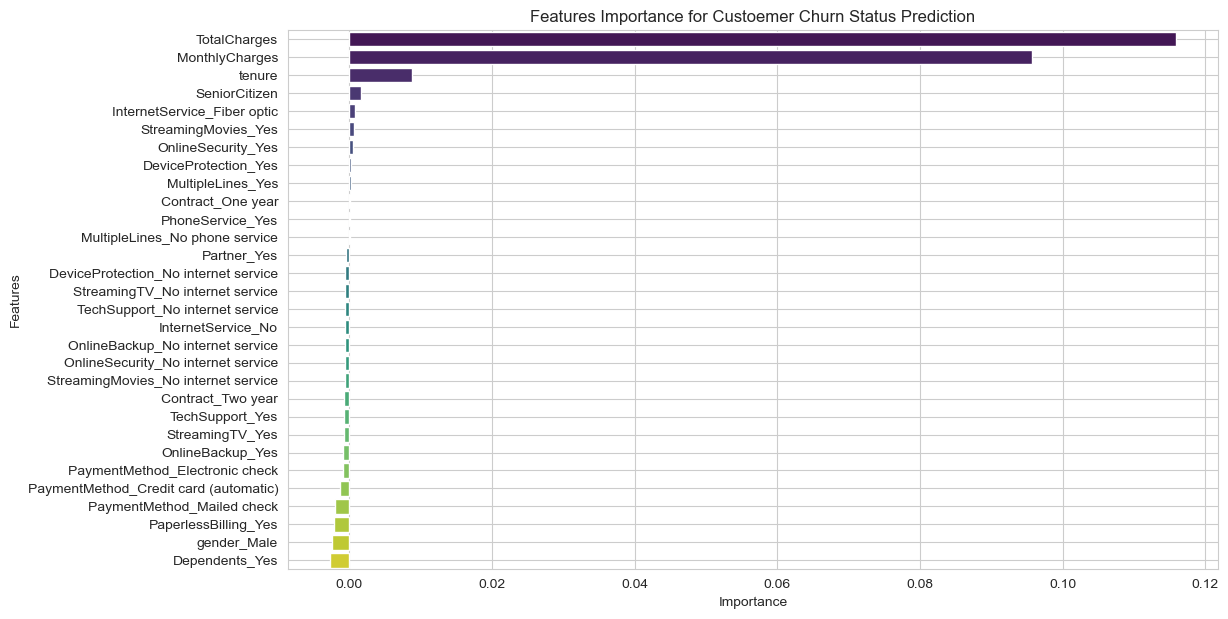

In [34]:
### Plot the Importance Plot
plt.figure(figsize=(12, 7))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')
plt.title('Features Importance for Custoemer Churn Status Prediction')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.grid(True)
plt.show()


### **Support Vectors Machines**

### **Default SVM**

In [40]:
### Initialize the Support Vectors Machines
from sklearn.svm import SVC

### Initialize the Training Process 
svm_model = SVC(random_state = 42)

### Train the Model
svm_model.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


## **Radial-Based Function Kernel**

In [41]:
from sklearn.svm import SVC

### Initialize the Training Process
svm_model = SVC(
    kernel='rbf',
    probability=True,   # VERY IMPORTANT
    random_state=42
)

### Train the Model
svm_model.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


##### **Using Linear Kernel**

In [42]:
#svm_model = SVC(kernel='linear')
#svm_model.fit(X_train, y_train)

### **Predict the Customer Churn Status**

In [43]:
### predict
svm_pred = svm_model.predict(X_test)
svm_pred[:5]

array(['No', 'No', 'No', 'No', 'No'], dtype=object)

### Evaluate the Performance

In [46]:
### Evaluate the Performance
accuracy = accuracy_score(y_test, svm_pred)
conf_matrix1 = confusion_matrix(y_test, svm_pred)
class_report = classification_report(y_test, svm_pred)
print(f"Accuracy: {accuracy:.4f}")
print(conf_matrix)

Accuracy: 0.7283
[[1539    0]
 [ 574    0]]


In [47]:
print(class_report)

              precision    recall  f1-score   support

          No       0.73      1.00      0.84      1539
         Yes       0.00      0.00      0.00       574

    accuracy                           0.73      2113
   macro avg       0.36      0.50      0.42      2113
weighted avg       0.53      0.73      0.61      2113



### Report of SVM Results

The Support Vector Machine (SVM) model achieved an overall **accuracy of 74%**, correctly classifying 1,409 observations. However, the dataset is imbalanced, with 1,036 non-churners (“No”) and 373 churners (“Yes”).

For the **“No” class**, the model achieved a **precision of 0.74** and a **recall of 1.00**, meaning it correctly identified all actual non-churners. The **F1-score of 0.85** indicates strong performance for this majority class. The perfect recall suggests the model predicted nearly all observations as “No.”

For the **“Yes” class**, the model performed extremely poorly. The **precision, recall, and F1-score are all 0.00**, indicating that the model failed to correctly identify any churners. In practical terms, the SVM did not detect a single positive case. This implies a severe class imbalance issue or that the model is biased toward predicting the majority class.

The **macro-average F1-score of 0.42** reflects poor balanced performance across classes, while the **weighted F1-score of 0.62** is inflated by the dominance of the majority class.

Overall, although the SVM achieved moderate accuracy, it completely failed in identifying churners, making it unsuitable for churn prediction without class balancing or model tuning.


#### **Confusion Matrix**

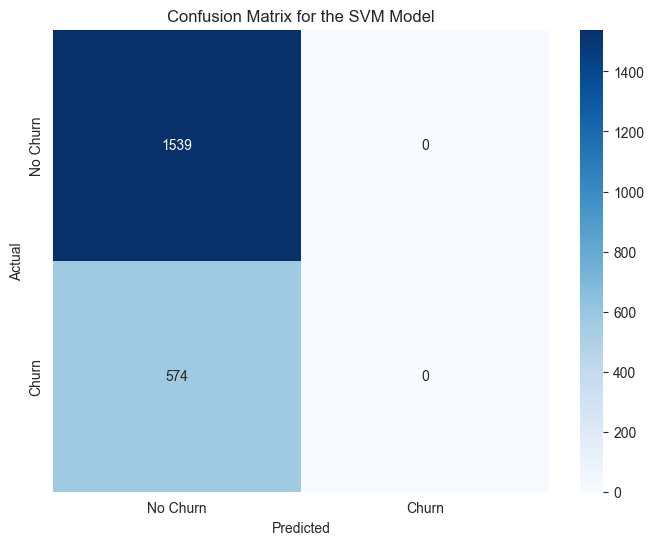

In [48]:
### Plot the Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix1, annot=True, fmt='d', cmap='Blues', xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.title('Confusion Matrix for the SVM Model')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


#### **ROC and AUC Value**

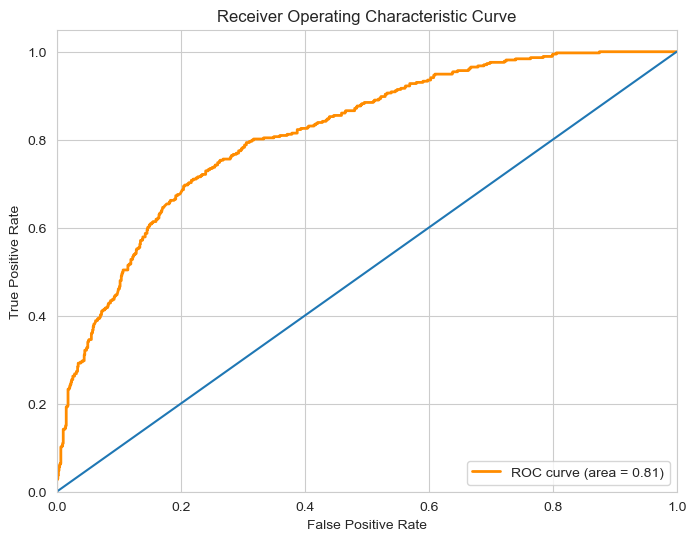

In [42]:
### Plot the ROC and AUC value
y_test_numeric = y_test.map({'Yes': 1, 'No': 0})
y_pred_prob = svm_model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test_numeric, y_pred_prob)
roc_auc = auc(fpr, tpr)


### Plot the ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1],[0,1])
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic Curve')
plt.legend(loc = 'lower right')
plt.grid(True)
plt.show()